# Activity 2: Spam Email Detection using Logistic Regression
Dataset: spam_email_dataset.csv https://www.kaggle.com/datasets/jackksoncsie/spam-email-dataset

Description: 6,000 records, 16 columns. Target Spam Indicator: 0 = Not Spam, 1 = Spam. Class counts: 3,018 Not Spam and 2,982 Spam. No missing values or duplicate rows were found.

Features: Attachments, Link Count, Word Count, Uppercase Count, Exclamation Count, Question Count, Dollar Count, Punctuation Count, HTML Tags Count. Identifier-like fields, sender/recipient, subject, date and time are excluded.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score,
    classification_report, roc_curve
)

df = pd.read_csv("spam_email_dataset.csv")

print("Dataset Shape:", df.shape)
print(df.head())
print(df.info())

Dataset Shape: (6000, 16)
                      Email  \
0     mikerusso@example.net   
1   waynebailey@example.org   
2        jill43@example.com   
3  johnsonkaren@example.org   
4    markwilson@example.org   

                                             Subject  \
0                       Even hotel community church.   
1  Try themselves guess fight white agreement thu...   
2  Environmental commercial off seem any conference.   
3      Smile real TV father commercial day increase.   
4                     Fast stage he oil institution.   

                     Sender                   Recipient        Date   Time  \
0    emilyscott@example.org    gregorysmith@example.org  13-02-2023  04:13   
1      annwhite@example.net  gonzalezdaniel@example.net  09-08-2023  06:15   
2       david88@example.net   michellebaker@example.net  16-05-2023  01:32   
3  lindaalvarez@example.com   schroedertodd@example.com  25-04-2023  14:50   
4     vstafford@example.com   emilywilliams@example.com  11-

# Step 2: Data inspection

In [2]:
print("Missing Values:")
print(df.isnull().sum())

print("Duplicate Records:", df.duplicated().sum())

print("Statistical Summary:")
print(df.describe())

Missing Values:
Email                0
Subject              0
Sender               0
Recipient            0
Date                 0
Time                 0
Attachments          0
Link Count           0
Word Count           0
Uppercase Count      0
Exclamation Count    0
Question Count       0
Dollar Count         0
Punctuation Count    0
HTML Tags Count      0
Spam Indicator       0
dtype: int64
Duplicate Records: 0
Statistical Summary:
       Attachments   Link Count   Word Count  Uppercase Count  \
count  6000.000000  6000.000000  6000.000000      6000.000000   
mean      1.497833     5.005500   153.269500        75.997667   
std       1.125555     3.166092    83.135747        64.735568   
min       0.000000     0.000000    10.000000         0.000000   
25%       0.000000     2.000000    83.000000        23.000000   
50%       1.000000     5.000000   154.000000        59.000000   
75%       3.000000     8.000000   223.000000       114.000000   
max       3.000000    10.000000   300.000

Spam Indicator
0    3018
1    2982
Name: count, dtype: int64


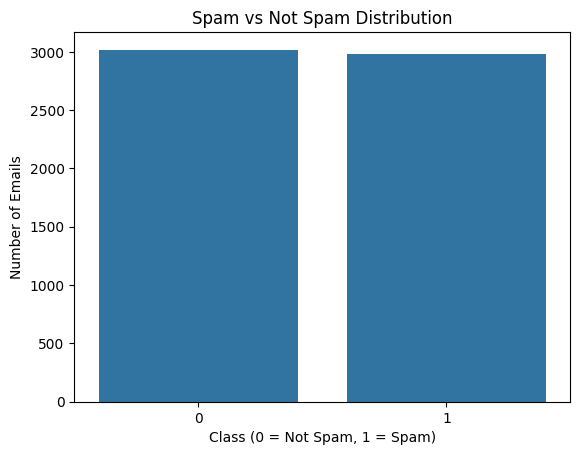

In [3]:
print(df["Spam Indicator"].value_counts())

sns.countplot(data=df, x="Spam Indicator")
plt.title("Spam vs Not Spam Distribution")
plt.xlabel("Class (0 = Not Spam, 1 = Spam)")
plt.ylabel("Number of Emails")
plt.show()

# Preparation and stratified split
There are no missing values, so imputation is unnecessary. No duplicate rows were found. The dataset is nearly balanced. We use a stratified 80:20 split with random_state=42. The scaler is fitted only on training data to avoid data leakage.

In [4]:
features = [
    "Attachments",
    "Link Count",
    "Word Count",
    "Uppercase Count",
    "Exclamation Count",
    "Question Count",
    "Dollar Count",
    "Punctuation Count",
    "HTML Tags Count"
]

X = df[features]
y = df["Spam Indicator"]

print("Input Features:", X.shape)
print("Target:", y.shape)

Input Features: (6000, 9)
Target: (6000,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Data: (4800, 9)
Testing Data: (1200, 9)

Training Class Distribution:
Spam Indicator
0    2414
1    2386
Name: count, dtype: int64

Testing Class Distribution:
Spam Indicator
0    604
1    596
Name: count, dtype: int64


In [6]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature Scaling Completed")

Feature Scaling Completed


# Logistic Regression and sigmoid
Linear Regression is intended for continuous outputs and can predict values outside 0–1. Logistic Regression applies the sigmoid function to a linear score to estimate a probability between 0 and 1. A decision threshold converts that probability to a class.

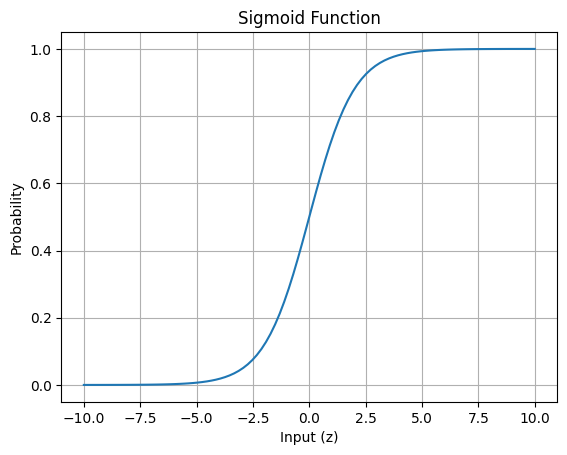

In [7]:
z = np.linspace(-10, 10, 100)

sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)
plt.title("Sigmoid Function")
plt.xlabel("Input (z)")
plt.ylabel("Probability")
plt.grid()
plt.show()

In [8]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Logistic Regression Model Trained Successfully")
print("Intercept:", model.intercept_)

coefficients = pd.DataFrame({
    "Feature": features,
    "Coefficient": model.coef_[0]
})

print(coefficients)

Logistic Regression Model Trained Successfully
Intercept: [-0.01168592]
             Feature  Coefficient
0        Attachments     0.029286
1         Link Count     0.020332
2         Word Count    -0.000200
3    Uppercase Count    -0.020695
4  Exclamation Count    -0.015564
5     Question Count    -0.076411
6       Dollar Count    -0.016801
7  Punctuation Count     0.004554
8    HTML Tags Count    -0.017248


In [9]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]

y_pred = model.predict(X_test_scaled)

result = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted Probability": y_prob,
    "Predicted Label": y_pred
})

print(result.head(10))

   Actual  Predicted Probability  Predicted Label
0       1               0.506424                1
1       0               0.503032                1
2       0               0.497487                0
3       1               0.507547                1
4       0               0.497794                0
5       0               0.510783                1
6       1               0.520432                1
7       1               0.480444                0
8       0               0.481596                0
9       0               0.511057                1


#  Confusion Matrix Interpretation

The confusion matrix gives the following results:

- True Negative (TN) = 323: Not Spam emails correctly predicted as Not Spam.
- False Positive (FP) = 281: Not Spam emails incorrectly predicted as Spam.
- False Negative (FN) = 317: Spam emails incorrectly predicted as Not Spam.
- True Positive (TP) = 279: Spam emails correctly predicted as Spam.

The model has both false positive and false negative predictions. Therefore, its classification performance needs improvement.

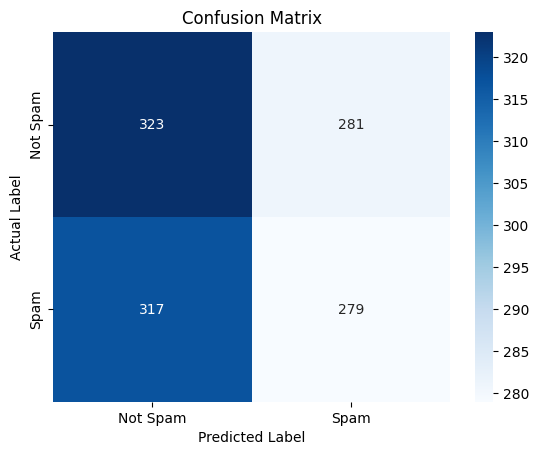

True Negative: 323
False Positive: 281
False Negative: 317
True Positive: 279


In [10]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Spam", "Spam"],
    yticklabels=["Not Spam", "Spam"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

TN, FP, FN, TP = cm.ravel()

print("True Negative:", TN)
print("False Positive:", FP)
print("False Negative:", FN)
print("True Positive:", TP)

In [11]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = TN / (TN + FP)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

Accuracy: 0.5016666666666667
Precision: 0.4982142857142857
Recall: 0.46812080536912754
Specificity: 0.5347682119205298
F1 Score: 0.4826989619377163
ROC-AUC: 0.49063013911729414


In [12]:
print(classification_report(
    y_test,
    y_pred,
    target_names=["Not Spam", "Spam"]
))

              precision    recall  f1-score   support

    Not Spam       0.50      0.53      0.52       604
        Spam       0.50      0.47      0.48       596

    accuracy                           0.50      1200
   macro avg       0.50      0.50      0.50      1200
weighted avg       0.50      0.50      0.50      1200



In [13]:
majority_class = y_train.value_counts().idxmax()

baseline_pred = np.full(
    len(y_test), majority_class
)

baseline_accuracy = accuracy_score(
    y_test, baseline_pred
)

print("Baseline Accuracy:", baseline_accuracy)
print("Logistic Regression Accuracy:", accuracy)

Baseline Accuracy: 0.5033333333333333
Logistic Regression Accuracy: 0.5016666666666667


# Threshold decision log
For spam filtering, false negatives allow spam into the inbox, while false positives may hide genuine messages. On this test split, threshold 0.3 labels all 1,200 emails as spam (recall 1.0 but low precision); threshold 0.7 labels none as spam (recall 0). Threshold 0.5 is the least-bad of these three in terms of accuracy/F1, but the model is still weak. Recommendation: do not deploy this model as an automatic filter. Improve features and choose a threshold using validation data and the organisation's actual error costs.

In [14]:
thresholds = [0.3, 0.5, 0.7]

threshold_results = []

for threshold in thresholds:

    pred = (y_prob >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Predicted Positive": sum(pred),
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

print(threshold_df)

   Threshold  Predicted Positive  Accuracy  Precision    Recall  F1 Score
0        0.3                1200  0.496667   0.496667  1.000000  0.663697
1        0.5                 560  0.501667   0.498214  0.468121  0.482699
2        0.7                   0  0.503333   0.000000  0.000000  0.000000


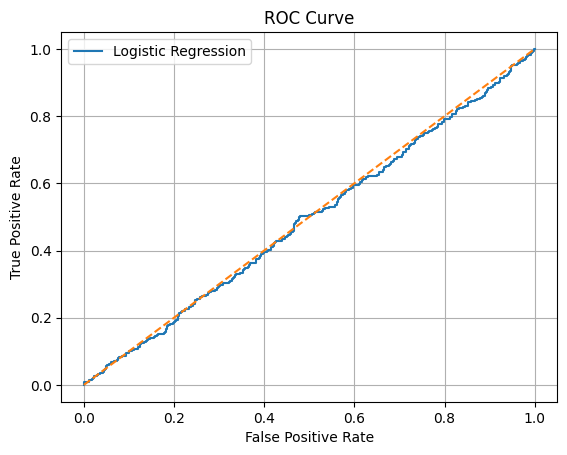

ROC-AUC: 0.49063013911729414


In [15]:
fpr, tpr, thresholds_roc = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr, label="Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--")

plt.title("ROC Curve")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.grid()
plt.show()

print("ROC-AUC:", roc_auc)

In [16]:
train_pred = model.predict(X_train_scaled)
test_pred = model.predict(X_test_scaled)

print("Training Accuracy:",
      accuracy_score(y_train, train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, test_pred))

Training Accuracy: 0.5139583333333333
Testing Accuracy: 0.5016666666666667


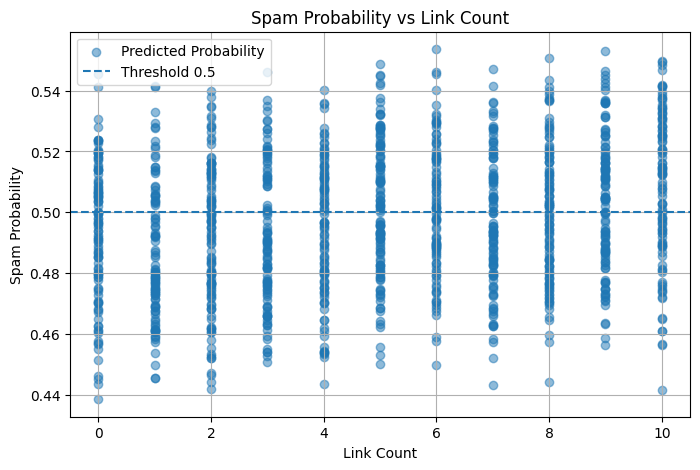

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test["Link Count"],
    y_prob,
    alpha=0.5,
    label="Predicted Probability"
)

plt.axhline(0.5, linestyle="--", label="Threshold 0.5")

plt.title("Spam Probability vs Link Count")
plt.xlabel("Link Count")
plt.ylabel("Spam Probability")
plt.legend()
plt.grid()
plt.show()

In [18]:
new_email = pd.DataFrame([{
    "Attachments": 1,
    "Link Count": 8,
    "Word Count": 120,
    "Uppercase Count": 80,
    "Exclamation Count": 4,
    "Question Count": 1,
    "Dollar Count": 2,
    "Punctuation Count": 10,
    "HTML Tags Count": 3
}])

new_scaled = scaler.transform(new_email)

probability = model.predict_proba(new_scaled)[0][1]

prediction = 1 if probability >= 0.5 else 0

print("Spam Probability:", probability)
print("Predicted Class:", prediction)

if prediction == 1:
    print("Email is Spam")
else:
    print("Email is Not Spam")

Spam Probability: 0.49749285086845496
Predicted Class: 0
Email is Not Spam


# Conclusion
The model was trained on nine numeric email features using a stratified 80:20 split. Test accuracy is about 50.17% and ROC-AUC is about 0.491; the majority-class baseline accuracy is about 50.33%. These results are close to chance and slightly below the baseline, so the selected features/model do not provide useful separation. Do not use this model to automatically classify or delete emails. Predictions are probability-based estimates, not guaranteed outcomes.

Limitations: The original public dataset URL was not supplied; only count-based numeric features were used; results are from one train/test split.